# Importing the dependencies

In [ ]:
!pip install -q lime

In [ ]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [ ]:
import json, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from zipfile import ZipFile
from sklearn.preprocessing import MinMaxScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix,  roc_curve, roc_auc_score

import lime
import lime.lime_tabular

# Data Collection and Analysis

In [ ]:
with ZipFile('kr62jwy9vw-1.zip', 'r') as zip_ref:
  zip_ref.extractall()

In [ ]:
df = pd.read_csv('bhutan_samples.csv')

df.head()

,FID,Type,Code,Lithology,Altitude,Slope,Total curvature,Aspect,Distance to road,Distance to stream,Slope length,TWI,STI
0,0,slide,1,1,1,2,1,7,1,5,2,4,1
1,1,slide,1,1,1,3,1,4,2,2,2,5,1
2,2,slide,1,1,1,2,3,7,1,1,1,3,0
3,3,slide,1,1,1,3,1,10,1,2,2,4,0
4,4,slide,1,1,1,3,1,10,1,4,3,5,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1221 entries, 0 to 1220
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   FID                 1221 non-null   int64 
 1   Type                1221 non-null   object
 2   Code                1221 non-null   int64 
 3   Lithology           1221 non-null   int64 
 4   Altitude            1221 non-null   int64 
 5   Slope               1221 non-null   int64 
 6   Total curvature     1221 non-null   int64 
 7   Aspect              1221 non-null   int64 
 8   Distance to road    1221 non-null   int64 
 9   Distance to stream  1221 non-null   int64 
 10  Slope length        1221 non-null   int64 
 11  TWI                 1221 non-null   int64 
 12  STI                 1221 non-null   int64 
dtypes: int64(12), object(1)
memory usage: 124.1+ KB


In [ ]:
df.shape

(1221, 13)

In [ ]:
df['Type'].value_counts()

,count
Type,
slide,952
nonslide,269


In [ ]:
df['Code'].value_counts()

,count
Code,
1,952
0,269


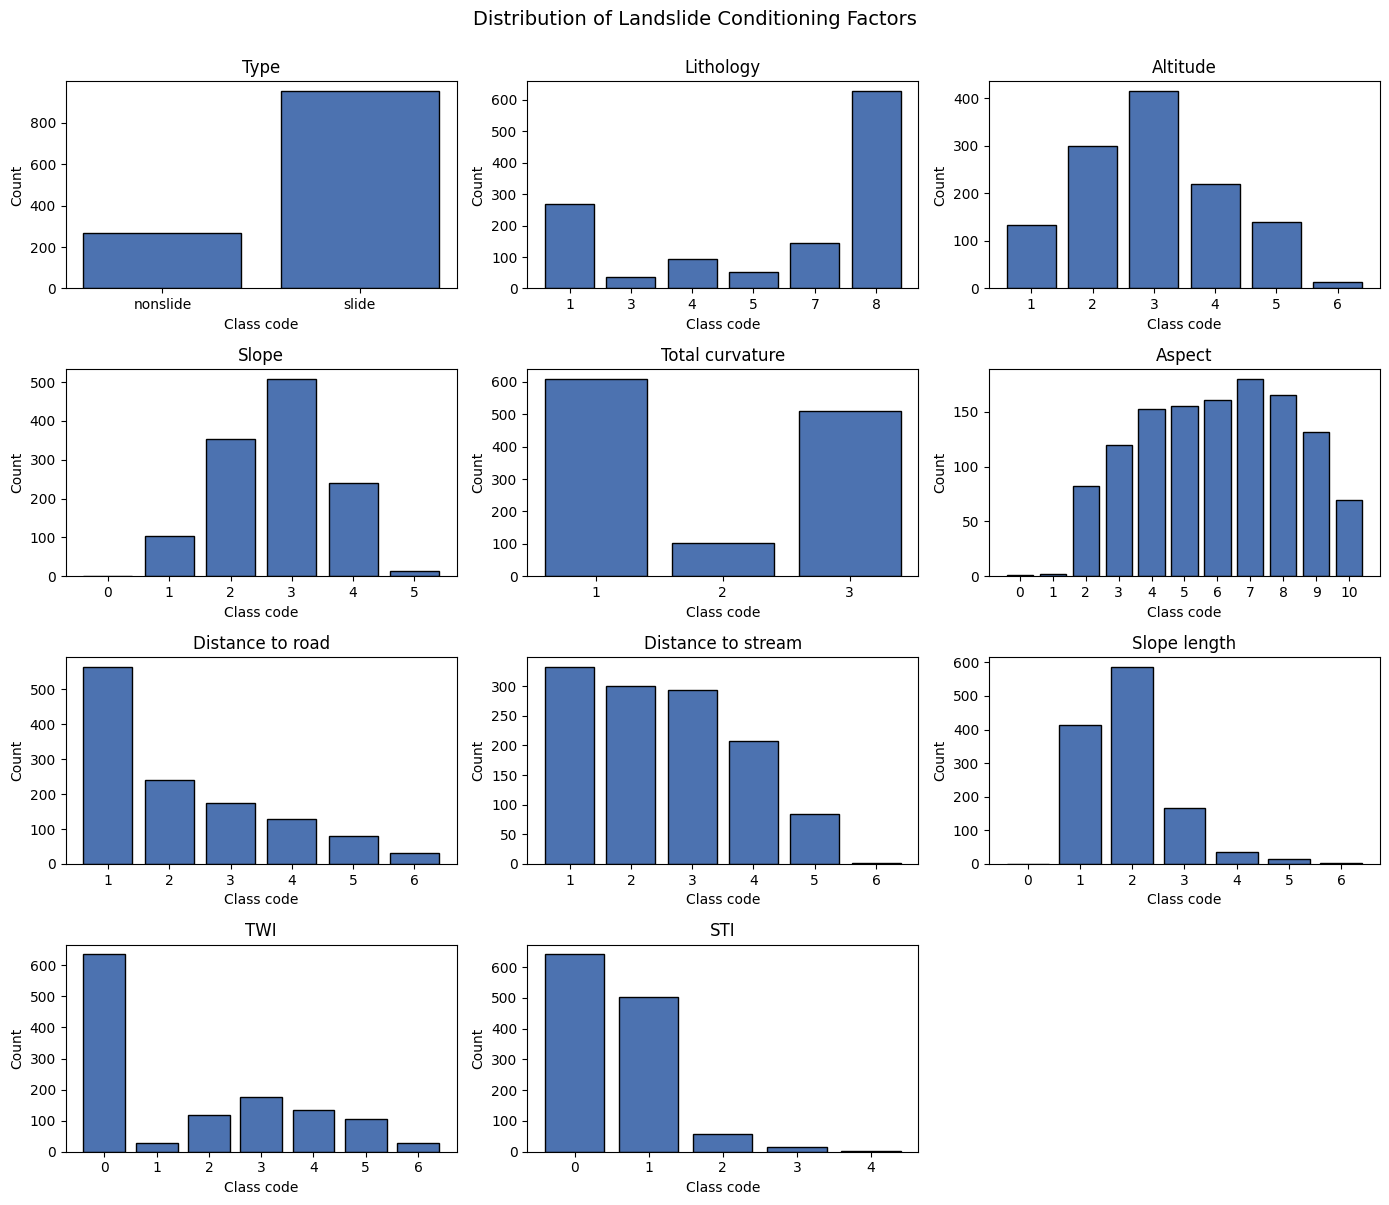

In [ ]:
feature_cols = [c for c in df.columns if c != 'Code' and c != 'FID']

fig, axes = plt.subplots(4, 3, figsize=(14, 12))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    counts = df[col].value_counts().sort_index()
    axes[i].bar(counts.index.astype(str), counts.values, color='#4C72B0', edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel('Class code')
    axes[i].set_ylabel('Count')

for j in range(len(feature_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Distribution of Landslide Conditioning Factors', fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

# Data Preprocessing

In [ ]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
FID,0
Type,0
Code,0
Lithology,0
Altitude,0
Slope,0
Total curvature,0
Aspect,0
Distance to road,0
Distance to stream,0


In [ ]:
df.drop(columns=['FID', 'Type'], inplace=True)
df.head()

,Code,Lithology,Altitude,Slope,Total curvature,Aspect,Distance to road,Distance to stream,Slope length,TWI,STI
0,1,1,1,2,1,7,1,5,2,4,1
1,1,1,1,3,1,4,2,2,2,5,1
2,1,1,1,2,3,7,1,1,1,3,0
3,1,1,1,3,1,10,1,2,2,4,0
4,1,1,1,3,1,10,1,4,3,5,0


In [ ]:
df.shape

(1221, 11)

Normalization

In [ ]:
scaler = MinMaxScaler()

X: Features, y: Target

In [ ]:
X = df.drop(columns=['Code'])
y = df['Code']

X.columns = X.columns.str.replace(' ', '_')

In [ ]:
X

,Lithology,Altitude,Slope,Total_curvature,Aspect,Distance_to_road,Distance_to_stream,Slope_length,TWI,STI
0,1,1,2,1,7,1,5,2,4,1
1,1,1,3,1,4,2,2,2,5,1
2,1,1,2,3,7,1,1,1,3,0
3,1,1,3,1,10,1,2,2,4,0
4,1,1,3,1,10,1,4,3,5,0
...,...,...,...,...,...,...,...,...,...,...
1216,5,4,2,1,7,1,1,2,5,1
1217,5,4,2,2,8,1,1,2,1,0
1218,5,5,3,2,8,1,5,2,4,0
1219,5,4,2,3,7,1,2,1,0,0


In [ ]:
y

,Code
0,1
1,1
2,1
3,1
4,1
...,...
1216,1
1217,1
1218,1
1219,1


Class Distribution before & after

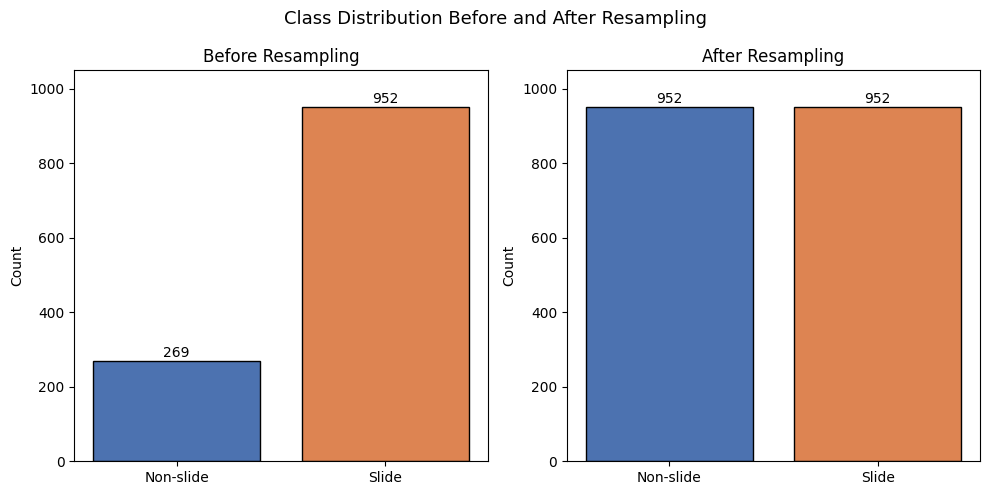

In [ ]:
X_scaled = scaler.fit_transform(X)
smote_demo = SMOTE(random_state=42)
X_res, y_res = smote_demo.fit_resample(X_scaled, y)

before_counts = y.value_counts().sort_index()
after_counts = pd.Series(y_res).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

labels = ['Non-slide', 'Slide']
colors = ['#4C72B0', '#DD8452']

axes[0].bar(labels, before_counts.values, color=colors, edgecolor='black')
axes[0].set_title('Before Resampling')
axes[0].set_ylabel('Count')
for i, v in enumerate(before_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center')

axes[1].bar(labels, after_counts.values, color=colors, edgecolor='black')
axes[1].set_title('After Resampling')
axes[1].set_ylabel('Count')
for i, v in enumerate(after_counts.values):
    axes[1].text(i, v + 10, str(v), ha='center')

axes[0].set_ylim(0, 1050)
axes[1].set_ylim(0, 1050)

plt.suptitle('Class Distribution Before and After Resampling', fontsize=13)
plt.tight_layout()
plt.show()

Correlation Matrix

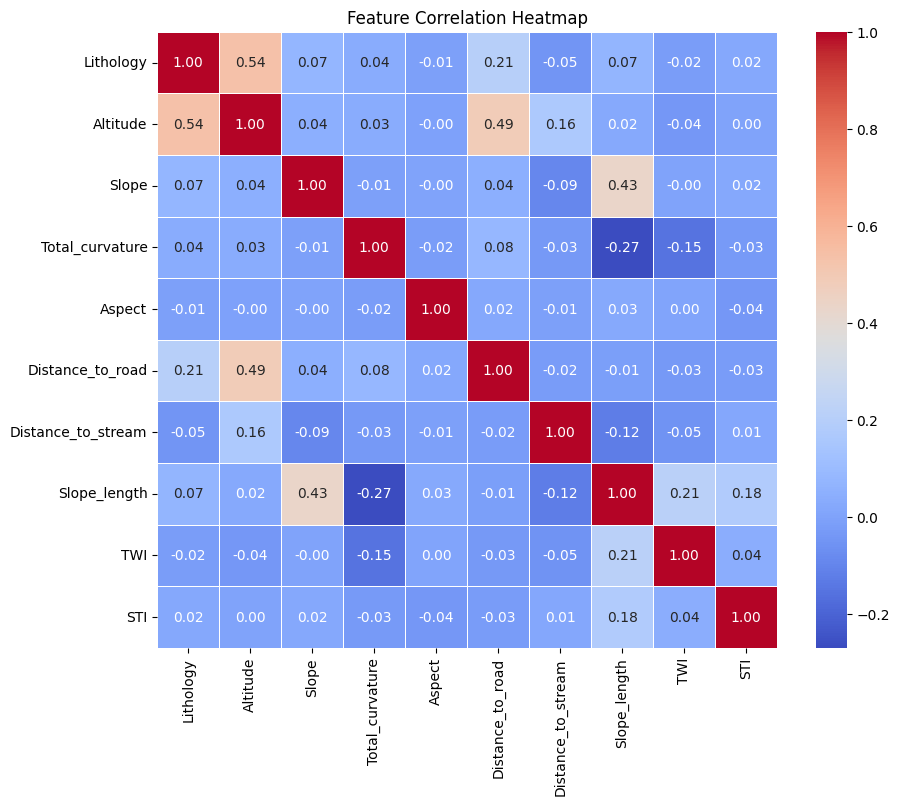

In [ ]:
plt.figure(figsize=(10, 8))
corr_matrix = X.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

# K-Fold cross-validation

In [ ]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

In [ ]:
def evaluate_model(name, pipeline, X, y, cv):

    y_pred = cross_val_predict(pipeline, X, y, cv=cv)

    cm = confusion_matrix(y, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Non-slide', 'Slide'],
                yticklabels=['Non-slide', 'Slide'])
    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    print(f"Classification Report:")
    print(classification_report(y, y_pred))

    scoring = ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted']
    scores = cross_validate(pipeline, X, y, cv=cv, scoring=scoring)

    return {
        "Model": name,
        "Accuracy_mean": scores['test_accuracy'].mean(),
        "Accuracy_std": scores['test_accuracy'].std(),
        "Precision_mean": scores['test_precision_weighted'].mean(),
        "Precision_std": scores['test_precision_weighted'].std(),
        "Recall_mean": scores['test_recall_weighted'].mean(),
        "Recall_std": scores['test_recall_weighted'].std(),
        "F1-Score_mean": scores['test_f1_weighted'].mean(),
        "F1-Score_std": scores['test_f1_weighted'].std()
    }

# Models

In [ ]:
log_reg_model = LogisticRegression(random_state=42, max_iter=1000)

log_reg_model

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model

DecisionTreeClassifier(random_state=42)

In [ ]:
rf_model = RandomForestClassifier(random_state=42)

rf_model

RandomForestClassifier(random_state=42)

In [ ]:
knn_model = KNeighborsClassifier()

knn_model

KNeighborsClassifier()

In [ ]:
xgb_model = XGBClassifier(random_state=42)

xgb_model

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
lgbm_model = LGBMClassifier(random_state=42, verbose=-1)

lgbm_model

LGBMClassifier(random_state=42, verbose=-1)

# Base Model Evaluation

In [ ]:
base_models = {
    "Logistic Regression": log_reg_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "K-Nearest Neighbors": knn_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model
}

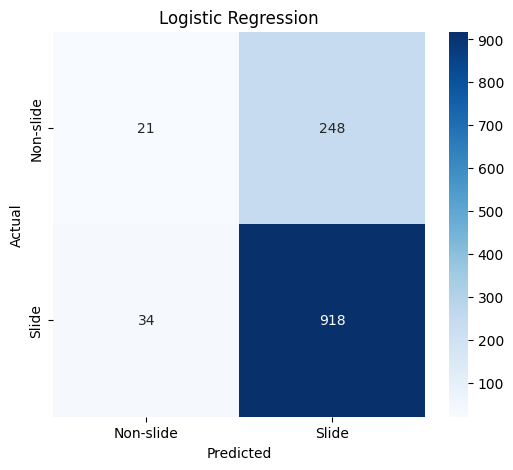

Classification Report:
              precision    recall  f1-score   support

           0       0.38      0.08      0.13       269
           1       0.79      0.96      0.87       952

    accuracy                           0.77      1221
   macro avg       0.58      0.52      0.50      1221
weighted avg       0.70      0.77      0.70      1221



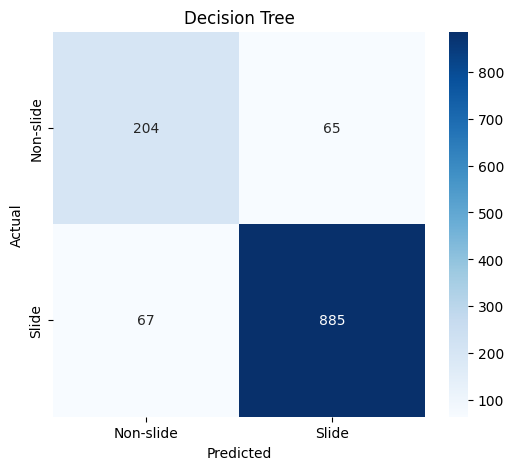

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.76      0.76       269
           1       0.93      0.93      0.93       952

    accuracy                           0.89      1221
   macro avg       0.84      0.84      0.84      1221
weighted avg       0.89      0.89      0.89      1221



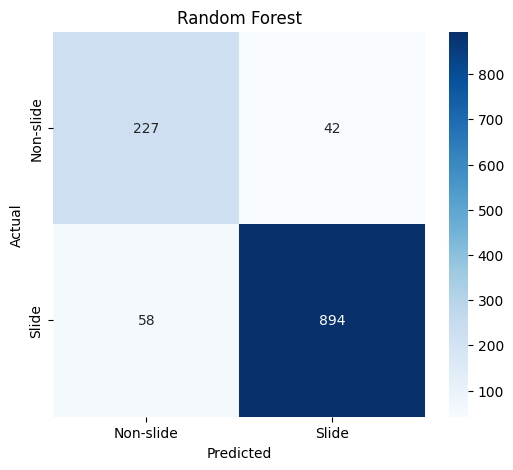

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.84      0.82       269
           1       0.96      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.89      0.88      1221
weighted avg       0.92      0.92      0.92      1221



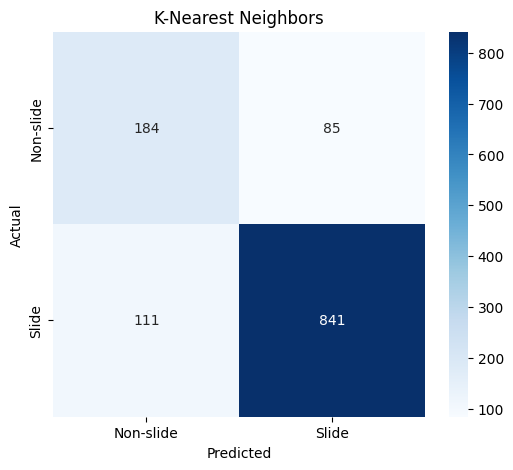

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.68      0.65       269
           1       0.91      0.88      0.90       952

    accuracy                           0.84      1221
   macro avg       0.77      0.78      0.77      1221
weighted avg       0.85      0.84      0.84      1221



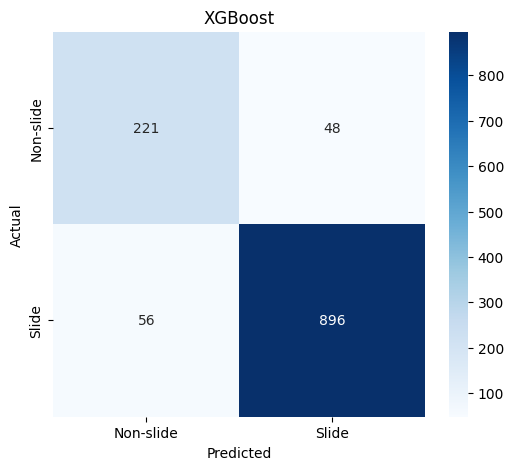

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.82      0.81       269
           1       0.95      0.94      0.95       952

    accuracy                           0.91      1221
   macro avg       0.87      0.88      0.88      1221
weighted avg       0.92      0.91      0.92      1221



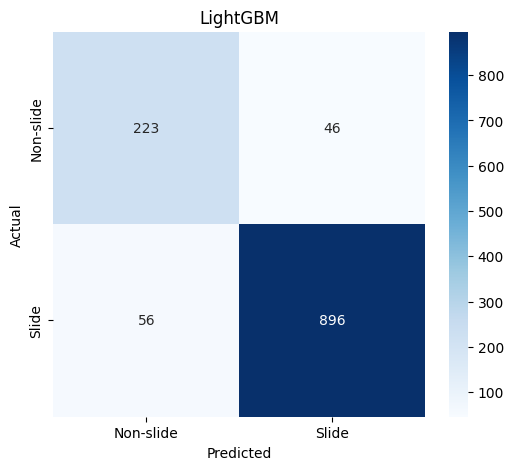

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       269
           1       0.95      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.89      0.88      1221
weighted avg       0.92      0.92      0.92      1221



In [ ]:
base_model_results = []

for name, model in base_models.items():
    pipeline = Pipeline([('scaler', scaler), ('model', model)])

    res_dict = evaluate_model(name, pipeline, X, y, cv)
    base_model_results.append(res_dict)

# Ablation study sampling techniques

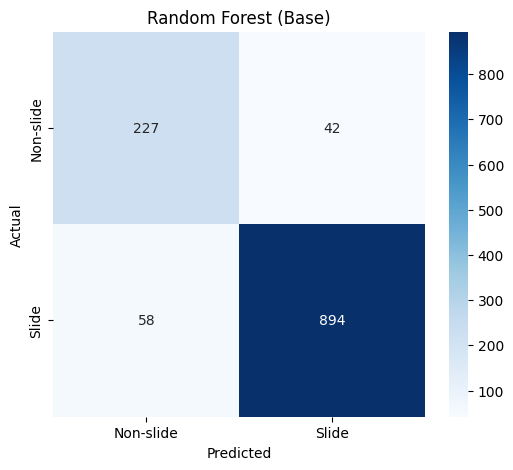

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.84      0.82       269
           1       0.96      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.89      0.88      1221
weighted avg       0.92      0.92      0.92      1221



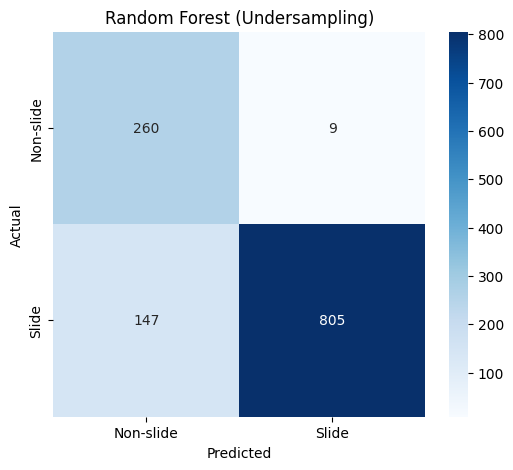

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.97      0.77       269
           1       0.99      0.85      0.91       952

    accuracy                           0.87      1221
   macro avg       0.81      0.91      0.84      1221
weighted avg       0.91      0.87      0.88      1221



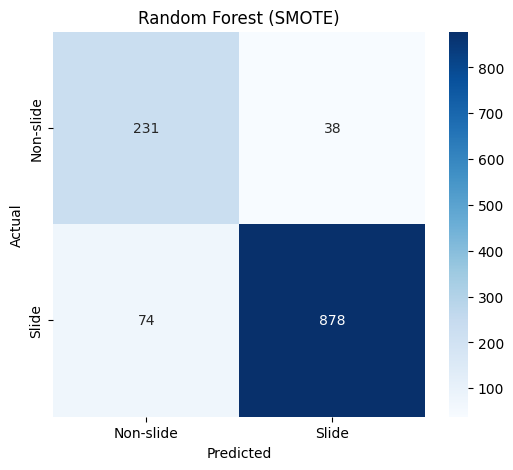

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.86      0.80       269
           1       0.96      0.92      0.94       952

    accuracy                           0.91      1221
   macro avg       0.86      0.89      0.87      1221
weighted avg       0.91      0.91      0.91      1221



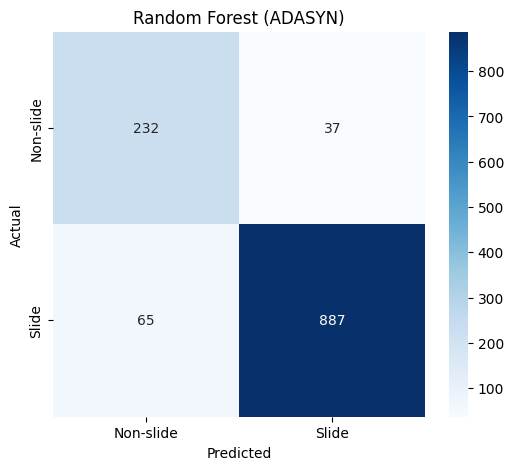

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.86      0.82       269
           1       0.96      0.93      0.95       952

    accuracy                           0.92      1221
   macro avg       0.87      0.90      0.88      1221
weighted avg       0.92      0.92      0.92      1221



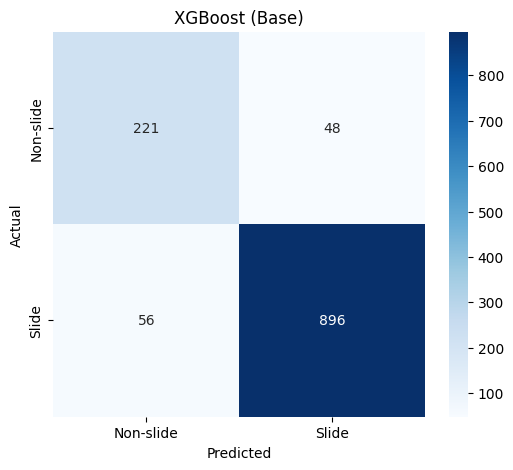

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.82      0.81       269
           1       0.95      0.94      0.95       952

    accuracy                           0.91      1221
   macro avg       0.87      0.88      0.88      1221
weighted avg       0.92      0.91      0.92      1221



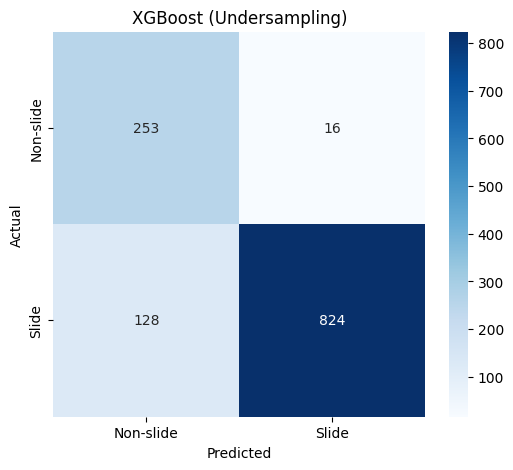

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.94      0.78       269
           1       0.98      0.87      0.92       952

    accuracy                           0.88      1221
   macro avg       0.82      0.90      0.85      1221
weighted avg       0.91      0.88      0.89      1221



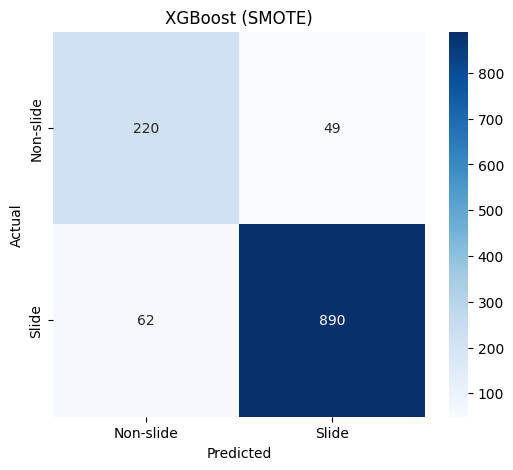

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.82      0.80       269
           1       0.95      0.93      0.94       952

    accuracy                           0.91      1221
   macro avg       0.86      0.88      0.87      1221
weighted avg       0.91      0.91      0.91      1221



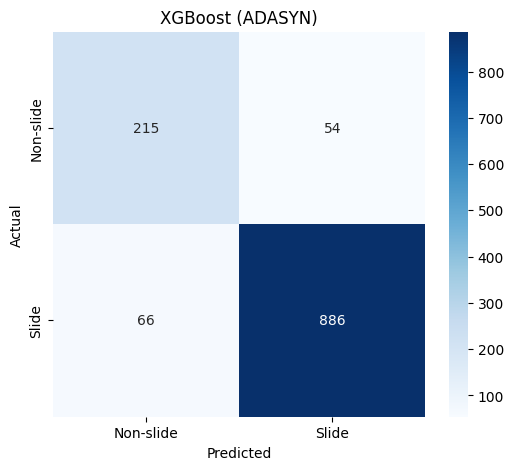

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.80      0.78       269
           1       0.94      0.93      0.94       952

    accuracy                           0.90      1221
   macro avg       0.85      0.86      0.86      1221
weighted avg       0.90      0.90      0.90      1221



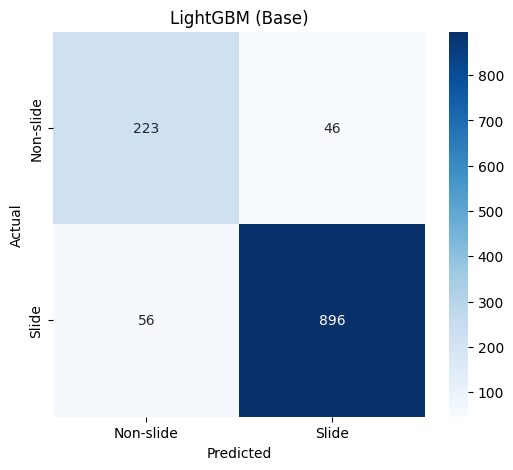

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       269
           1       0.95      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.89      0.88      1221
weighted avg       0.92      0.92      0.92      1221



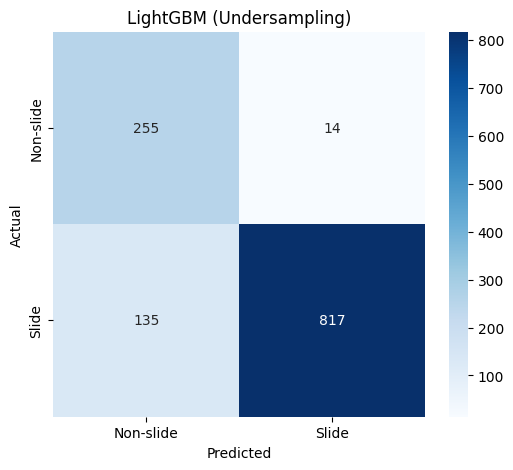

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.95      0.77       269
           1       0.98      0.86      0.92       952

    accuracy                           0.88      1221
   macro avg       0.82      0.90      0.85      1221
weighted avg       0.91      0.88      0.89      1221



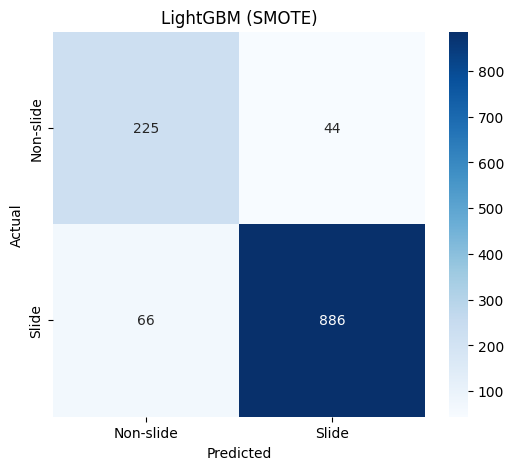

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.84      0.80       269
           1       0.95      0.93      0.94       952

    accuracy                           0.91      1221
   macro avg       0.86      0.88      0.87      1221
weighted avg       0.91      0.91      0.91      1221



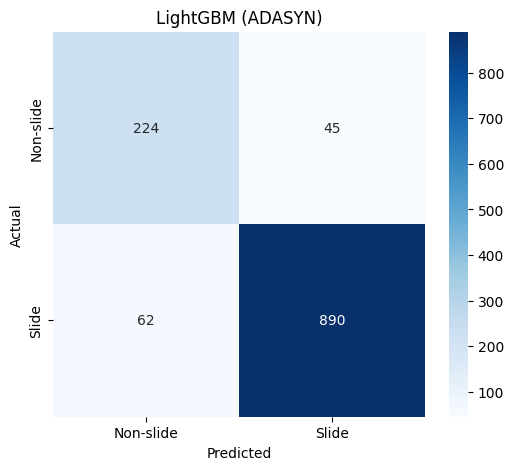

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.83      0.81       269
           1       0.95      0.93      0.94       952

    accuracy                           0.91      1221
   macro avg       0.87      0.88      0.88      1221
weighted avg       0.91      0.91      0.91      1221



In [ ]:
resampling_base_models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model,
}

resamplers = {
    "Base": None,
    "Undersampling": RandomUnderSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
    "ADASYN": ADASYN(random_state=42),
}

resampling_results = []
for model_name, model in resampling_base_models.items():
    for method_name, sampler in resamplers.items():
        steps = [('scaler', scaler)]
        if sampler is not None:
            steps.append(('sampler', sampler))
        steps.append(('model', model))
        pipeline = ImbPipeline(steps)

        res_dict = evaluate_model(f"{model_name} ({method_name})", pipeline, X, y, cv)
        res_dict["Model"] = model_name
        res_dict["Method"] = method_name
        resampling_results.append(res_dict)

In [ ]:
resampling_df = pd.DataFrame(resampling_results)

metric_cols = ['Accuracy', 'F1-Score']
for col in metric_cols:
    mean_fmt = (resampling_df[f'{col}_mean'] * 100).map('{:.2f}'.format)
    std_fmt  = (resampling_df[f'{col}_std'] * 100).map('{:.2f}'.format)
    resampling_df[col] = mean_fmt + " ± " + std_fmt

resampling_comparison_wide = resampling_df.pivot(index='Model', columns='Method', values=metric_cols)
resampling_comparison_wide = resampling_comparison_wide.swaplevel(0, 1, axis=1)
resampling_comparison_wide = resampling_comparison_wide.reindex(columns=['Base', 'Undersampling', 'SMOTE', 'ADASYN'], level=0)
resampling_comparison_wide = resampling_comparison_wide.reindex(index=['Random Forest', 'XGBoost', 'LightGBM'])

resampling_comparison_wide

Method                 Base               Undersampling                \
                   Accuracy      F1-Score      Accuracy      F1-Score   
Model                                                                   
Random Forest  91.81 ± 3.26  91.88 ± 3.21  87.23 ± 3.05  88.04 ± 2.77   
XGBoost        91.49 ± 3.12  91.54 ± 3.04  88.21 ± 1.70  88.86 ± 1.55   
LightGBM       91.65 ± 3.63  91.71 ± 3.56  87.80 ± 1.70  88.51 ± 1.54   

Method                SMOTE                      ADASYN                
                   Accuracy      F1-Score      Accuracy      F1-Score  
Model                                                                  
Random Forest  90.83 ± 3.67  91.03 ± 3.53  91.65 ± 3.06  91.79 ± 2.92  
XGBoost        90.91 ± 3.78  90.99 ± 3.67  90.18 ± 4.38  90.24 ± 4.33  
LightGBM       91.00 ± 3.74  91.13 ± 3.61  91.24 ± 3.75  91.36 ± 3.60

# Hyperparameter tuning

Random Forest - RandomizedSearchCV

In [ ]:
rscv_rf_grid = {
    'n_estimators': [int(x) for x in np.linspace(start = 200, stop = 2000, num = 10)],
    'max_depth': [int(x) for x in np.linspace(10, 1000, 10)],
    'min_samples_split': [2, 6, 9, 12, 15],
    'min_samples_leaf': [1, 2, 4, 6, 8],
    'max_features': ['sqrt', 'log2'],
    'criterion': ['entropy','gini']
}

rf = RandomForestClassifier(random_state=42)
rf_randomcv = RandomizedSearchCV(estimator=rf, param_distributions=rscv_rf_grid, n_iter=100, cv=3,
                       random_state=42, n_jobs=-1, verbose=2)

rf_randomcv.fit(X, y)

Fitting 3 folds for each of 100 candidates, totalling 300 fits


RandomizedSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42),
                   n_iter=100, n_jobs=-1,
                   param_distributions={'criterion': ['entropy', 'gini'],
                                        'max_depth': [10, 120, 230, 340, 450,
                                                      560, 670, 780, 890,
                                                      1000],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2, 4, 6, 8],
                                        'min_samples_split': [2, 6, 9, 12, 15],
                                        'n_estimators': [200, 400, 600, 800,
                                                         1000, 1200, 1400, 1600,
                                                         1800, 2000]},
                   random_state=42, verbose=2)

In [ ]:
rf_randomcv.best_params_

{'n_estimators': 1200,
 'min_samples_split': 2,
 'min_samples_leaf': 2,
 'max_features': 'sqrt',
 'max_depth': 1000,
 'criterion': 'entropy'}

Random Forest - GridSearchCV

In [ ]:
gscv_rf_grid = {
    'criterion': [rf_randomcv.best_params_['criterion']],
    'max_depth': [rf_randomcv.best_params_['max_depth']],
    'max_features': [rf_randomcv.best_params_['max_features']],
    'min_samples_leaf': [rf_randomcv.best_params_['min_samples_leaf'],
                         rf_randomcv.best_params_['min_samples_leaf'] + 2,
                         rf_randomcv.best_params_['min_samples_leaf'] + 4],
    'min_samples_split': list(set([
        max(2, rf_randomcv.best_params_['min_samples_split'] - 2),
        max(2, rf_randomcv.best_params_['min_samples_split'] - 1),
        rf_randomcv.best_params_['min_samples_split'],
        rf_randomcv.best_params_['min_samples_split'] + 1,
        rf_randomcv.best_params_['min_samples_split'] + 2
    ])),
    'n_estimators': list(set([
        max(10, rf_randomcv.best_params_['n_estimators'] - 200),
        max(10, rf_randomcv.best_params_['n_estimators'] - 100),
        rf_randomcv.best_params_['n_estimators'],
        rf_randomcv.best_params_['n_estimators'] + 100,
        rf_randomcv.best_params_['n_estimators'] + 200
    ]))
}

rf = RandomForestClassifier(random_state=42)
rf_gridcv = GridSearchCV(estimator=rf, param_grid=gscv_rf_grid, cv=10,
                       n_jobs=-1, verbose=2)

rf_gridcv.fit(X, y)

Fitting 10 folds for each of 45 candidates, totalling 450 fits


GridSearchCV(cv=10, estimator=RandomForestClassifier(random_state=42),
             n_jobs=-1,
             param_grid={'criterion': ['entropy'], 'max_depth': [1000],
                         'max_features': ['sqrt'],
                         'min_samples_leaf': [2, 4, 6],
                         'min_samples_split': [2, 3, 4],
                         'n_estimators': [1000, 1100, 1200, 1300, 1400]},
             verbose=2)

In [ ]:
rf_gridcv.best_params_

{'criterion': 'entropy',
 'max_depth': 1000,
 'max_features': 'sqrt',
 'min_samples_leaf': 2,
 'min_samples_split': 2,
 'n_estimators': 1300}

XGBoost - RandomizedSearchCV

In [ ]:
rscv_xgb_grid = {
    'n_estimators': [50, 100, 150, 200, 300, 400],
    'max_depth': [2, 3, 4, 5],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5, 7, 10],
    'gamma': [0, 0.1, 0.3, 0.5]
}

xgb = XGBClassifier(random_state=42)
xgb_randomcv = RandomizedSearchCV(estimator=xgb, param_distributions=rscv_xgb_grid, n_iter=100, cv=5,
                       scoring='f1_weighted', random_state=42, n_jobs=-1, verbose=2)

xgb_randomcv.fit(X, y)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric=None, feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constrain...
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=100, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 0.9,
                                                             1.0],
                                        'gamma': [0, 0.1, 0.3, 0.5],
                                        'learning_rate': [0.01, 0.03, 0.05, 0.1,
                                                          0.15],
                                        'max_depth': [2, 3, 4, 5],
                                        'min_child_weight': [1, 3, 5, 7, 10],
                                        'n_estimators': [50, 100, 150, 200, 300,
                                                         400],
                                        'subsample': [0.7, 0.8, 0.9, 1.0]},
                   random_state=42, scoring='f1_weighted', verbose=2)

In [ ]:
xgb_randomcv.best_params_

{'subsample': 0.7,
 'n_estimators': 100,
 'min_child_weight': 1,
 'max_depth': 4,
 'learning_rate': 0.1,
 'gamma': 0,
 'colsample_bytree': 0.8}

XGBoost - GridSearchCV

In [ ]:
gscv_xgb_grid = {
    'max_depth': list(set([
        max(1, xgb_randomcv.best_params_['max_depth'] - 1),
        xgb_randomcv.best_params_['max_depth'],
        xgb_randomcv.best_params_['max_depth'] + 1
    ])),
    'learning_rate': list(set([
        round(max(0.001, xgb_randomcv.best_params_['learning_rate'] - 0.05), 3),
        xgb_randomcv.best_params_['learning_rate'],
        round(xgb_randomcv.best_params_['learning_rate'] + 0.05, 3)
    ])),
    'subsample': [xgb_randomcv.best_params_['subsample']],
    'colsample_bytree': [xgb_randomcv.best_params_['colsample_bytree']],
    'gamma': [xgb_randomcv.best_params_['gamma']],
    'min_child_weight': [xgb_randomcv.best_params_['min_child_weight']],
    'n_estimators': list(set([
        max(10, xgb_randomcv.best_params_['n_estimators'] - 200),
        max(10, xgb_randomcv.best_params_['n_estimators'] - 100),
        xgb_randomcv.best_params_['n_estimators'],
        xgb_randomcv.best_params_['n_estimators'] + 100,
        xgb_randomcv.best_params_['n_estimators'] + 200
    ]))
}

xgb_gridcv = GridSearchCV(estimator=xgb, param_grid=gscv_xgb_grid, cv=10,
                       scoring='f1_weighted', n_jobs=-1, verbose=2)

xgb_gridcv.fit(X, y)

Fitting 10 folds for each of 36 candidates, totalling 360 fits


GridSearchCV(cv=10,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=No...
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8], 'gamma': [0],
                         'learning_rate': [0.05, 0.1, 0.15],
                         'max_depth': [3, 4, 5], 'min_child_weight': [1],
                         'n_estimators': [200, 10, 100, 300],
                         'subsample': [0.7]},
             scoring='f1_weighted', verbose=2)

In [ ]:
xgb_gridcv.best_params_

{'colsample_bytree': 0.8,
 'gamma': 0,
 'learning_rate': 0.05,
 'max_depth': 5,
 'min_child_weight': 1,
 'n_estimators': 100,
 'subsample': 0.7}

LightGBM - RandomizedSearchCV

In [ ]:
rscv_lgbm_grid = {
    'n_estimators': [50, 100, 150, 200, 300, 400],
    'max_depth': [2, 3, 4, 5, -1],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],
    'num_leaves': [7, 15, 31],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'min_child_samples': [10, 20, 30, 50]
}

lgbm = LGBMClassifier(random_state=42, verbose=-1)
lgbm_randomcv = RandomizedSearchCV(estimator=lgbm, param_distributions=rscv_lgbm_grid, n_iter=100, cv=5,
                       scoring='f1_weighted', random_state=42, n_jobs=-1, verbose=2)

lgbm_randomcv.fit(X, y)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


RandomizedSearchCV(cv=5, estimator=LGBMClassifier(random_state=42, verbose=-1),
                   n_iter=100, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 0.9,
                                                             1.0],
                                        'learning_rate': [0.01, 0.03, 0.05, 0.1,
                                                          0.15],
                                        'max_depth': [2, 3, 4, 5, -1],
                                        'min_child_samples': [10, 20, 30, 50],
                                        'n_estimators': [50, 100, 150, 200, 300,
                                                         400],
                                        'num_leaves': [7, 15, 31],
                                        'subsample': [0.7, 0.8, 0.9, 1.0]},
                   random_state=42, scoring='f1_weighted', verbose=2)

In [ ]:
lgbm_randomcv.best_params_

{'subsample': 0.8,
 'num_leaves': 31,
 'n_estimators': 400,
 'min_child_samples': 30,
 'max_depth': 4,
 'learning_rate': 0.01,
 'colsample_bytree': 0.8}

LightGBM - GridSearchCV

In [ ]:
gscv_lgbm_grid = {
    'max_depth': [lgbm_randomcv.best_params_['max_depth']],
    'learning_rate': list(set([
        round(max(0.005, lgbm_randomcv.best_params_['learning_rate'] - 0.02), 3),
        lgbm_randomcv.best_params_['learning_rate'],
        round(lgbm_randomcv.best_params_['learning_rate'] + 0.02, 3)
    ])),
    'num_leaves': list(set([
        max(2, lgbm_randomcv.best_params_['num_leaves'] - 8),
        lgbm_randomcv.best_params_['num_leaves'],
        lgbm_randomcv.best_params_['num_leaves'] + 8
    ])),
    'subsample': [lgbm_randomcv.best_params_['subsample']],
    'colsample_bytree': [lgbm_randomcv.best_params_['colsample_bytree']],
    'min_child_samples': [lgbm_randomcv.best_params_['min_child_samples']],
    'n_estimators': list(set([
        max(10, lgbm_randomcv.best_params_['n_estimators'] - 50),
        lgbm_randomcv.best_params_['n_estimators'],
        lgbm_randomcv.best_params_['n_estimators'] + 50,
        lgbm_randomcv.best_params_['n_estimators'] + 100
    ]))
}

lgbm = LGBMClassifier(random_state=42, verbose=-1)
lgbm_gridcv = GridSearchCV(estimator=lgbm, param_grid=gscv_lgbm_grid, cv=10,
                       scoring='f1_weighted', n_jobs=-1, verbose=2)

lgbm_gridcv.fit(X, y)

Fitting 10 folds for each of 36 candidates, totalling 360 fits


GridSearchCV(cv=10, estimator=LGBMClassifier(random_state=42, verbose=-1),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8],
                         'learning_rate': [0.03, 0.01, 0.005], 'max_depth': [4],
                         'min_child_samples': [30],
                         'n_estimators': [400, 450, 500, 350],
                         'num_leaves': [31, 39, 23], 'subsample': [0.8]},
             scoring='f1_weighted', verbose=2)

In [ ]:
lgbm_gridcv.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.01,
 'max_depth': 4,
 'min_child_samples': 30,
 'n_estimators': 400,
 'num_leaves': 31,
 'subsample': 0.8}

# Hypertuning ablation study

In [ ]:
rf_rscv_best_params = {
    'n_estimators': 1200,
    'min_samples_split': 2,
    'min_samples_leaf': 2,
    'max_features': 'sqrt',
    'max_depth': 1000,
    'criterion': 'entropy'
}

rf_model_rscv = RandomForestClassifier(random_state=42, **rf_rscv_best_params)

rf_model_rscv

RandomForestClassifier(criterion='entropy', max_depth=1000, min_samples_leaf=2,
                       n_estimators=1200, random_state=42)

In [ ]:
rf_gscv_best_params = {
    'criterion': 'entropy',
    'max_depth': 1000,
    'max_features': 'sqrt',
    'min_samples_leaf': 2,
    'min_samples_split': 2,
    'n_estimators': 1300
}

rf_model_gscv = RandomForestClassifier(random_state=42, **rf_gscv_best_params)

rf_model_gscv

RandomForestClassifier(criterion='entropy', max_depth=1000, min_samples_leaf=2,
                       n_estimators=1300, random_state=42)

In [ ]:
xgb_rscv_best_params = {
    'subsample': 0.7,
    'n_estimators': 100,
    'min_child_weight': 1,
    'max_depth': 4,
    'learning_rate': 0.1,
    'gamma': 0,
    'colsample_bytree': 0.8
}

xgb_model_rscv = XGBClassifier(random_state=42, **xgb_rscv_best_params)

xgb_model_rscv

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=0, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
xgb_gscv_best_params = {
    'colsample_bytree': 0.8,
    'gamma': 0,
    'learning_rate': 0.05,
    'max_depth': 5,
    'min_child_weight': 1,
    'n_estimators': 100,
    'subsample': 0.7
}

xgb_model_gscv = XGBClassifier(random_state=42, **xgb_gscv_best_params)

xgb_model_gscv

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=0, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
lgbm_rscv_best_params = {
    'subsample': 0.8,
    'num_leaves': 31,
    'n_estimators': 400,
    'min_child_samples': 30,
    'max_depth': 4,
    'learning_rate': 0.01,
    'colsample_bytree': 0.8
}

lgbm_model_rscv = LGBMClassifier(random_state=42, verbose=-1, **lgbm_rscv_best_params)

lgbm_model_rscv

LGBMClassifier(colsample_bytree=0.8, learning_rate=0.01, max_depth=4,
               min_child_samples=30, n_estimators=400, random_state=42,
               subsample=0.8, verbose=-1)

In [ ]:
lgbm_gscv_best_params = {
    'colsample_bytree': 0.8,
    'learning_rate': 0.01,
    'max_depth': 4,
    'min_child_samples': 30,
    'n_estimators': 400,
    'num_leaves': 31,
    'subsample': 0.8
}

lgbm_model_gscv = LGBMClassifier(random_state=42, verbose=-1, **lgbm_gscv_best_params)

lgbm_model_gscv

LGBMClassifier(colsample_bytree=0.8, learning_rate=0.01, max_depth=4,
               min_child_samples=30, n_estimators=400, random_state=42,
               subsample=0.8, verbose=-1)

In [ ]:
tuned_models = {
    "Base RF": rf_model,
    "Base XGBoost": xgb_model,
    "Base LightGBM": lgbm_model,
    "RF + RSCV": rf_model_rscv,
    "RF + GSCV": rf_model_gscv,
    "XGBoost + RSCV": xgb_model_rscv,
    "XGBoost + GSCV": xgb_model_gscv,
    "LightGBM + RSCV": lgbm_model_rscv,
    "LightGBM + GSCV": lgbm_model_gscv
}

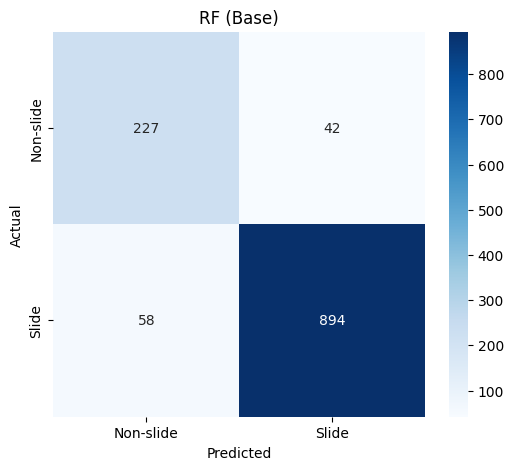

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.84      0.82       269
           1       0.96      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.89      0.88      1221
weighted avg       0.92      0.92      0.92      1221



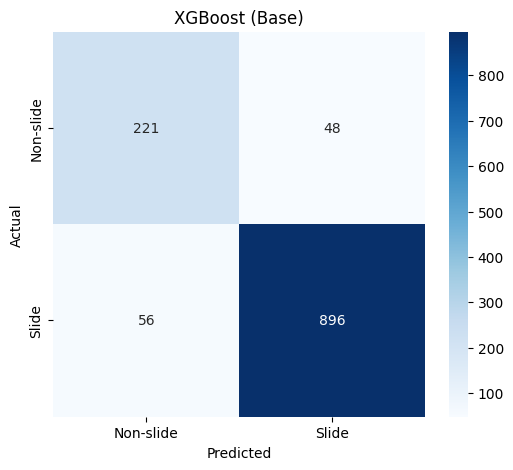

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.82      0.81       269
           1       0.95      0.94      0.95       952

    accuracy                           0.91      1221
   macro avg       0.87      0.88      0.88      1221
weighted avg       0.92      0.91      0.92      1221



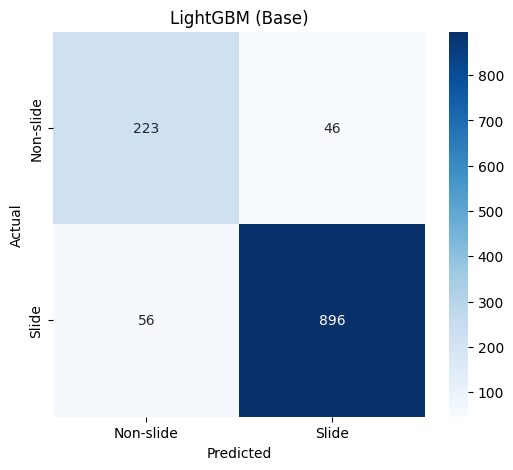

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       269
           1       0.95      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.89      0.88      1221
weighted avg       0.92      0.92      0.92      1221



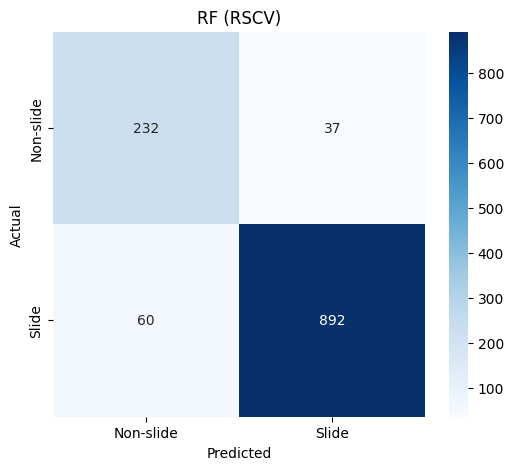

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.86      0.83       269
           1       0.96      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.90      0.89      1221
weighted avg       0.92      0.92      0.92      1221



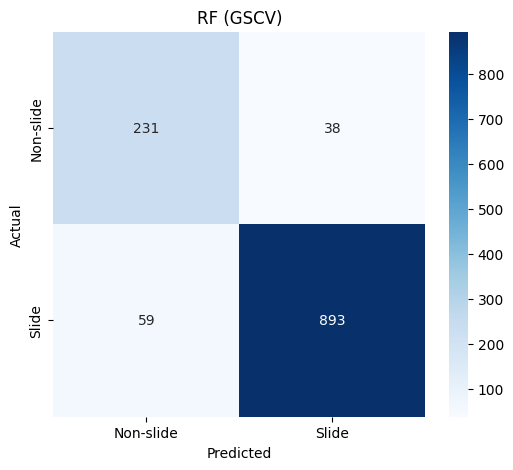

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.86      0.83       269
           1       0.96      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.90      0.89      1221
weighted avg       0.92      0.92      0.92      1221



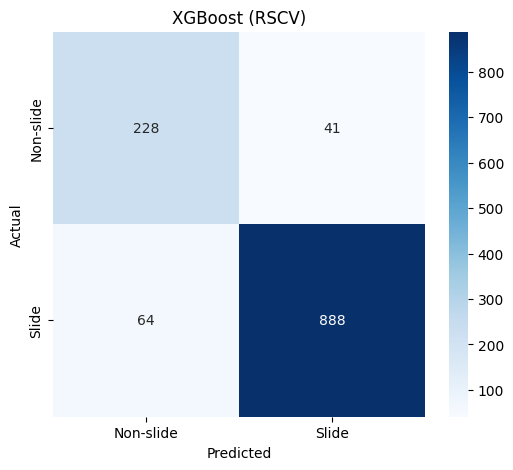

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.85      0.81       269
           1       0.96      0.93      0.94       952

    accuracy                           0.91      1221
   macro avg       0.87      0.89      0.88      1221
weighted avg       0.92      0.91      0.92      1221



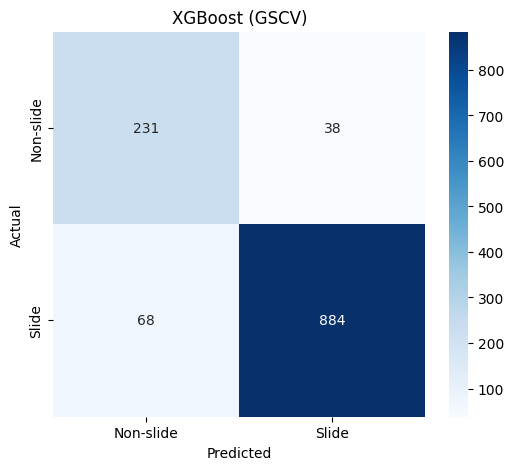

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.81       269
           1       0.96      0.93      0.94       952

    accuracy                           0.91      1221
   macro avg       0.87      0.89      0.88      1221
weighted avg       0.92      0.91      0.91      1221



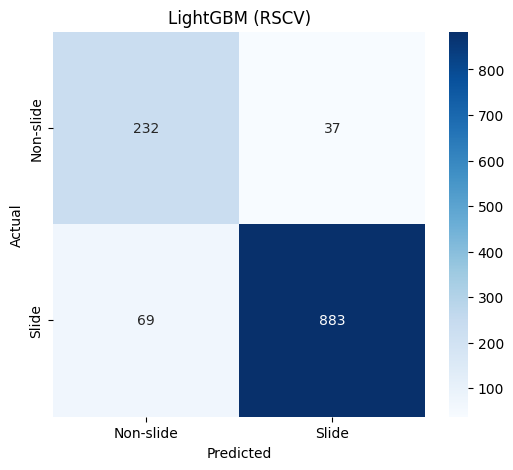

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.81       269
           1       0.96      0.93      0.94       952

    accuracy                           0.91      1221
   macro avg       0.87      0.89      0.88      1221
weighted avg       0.92      0.91      0.91      1221



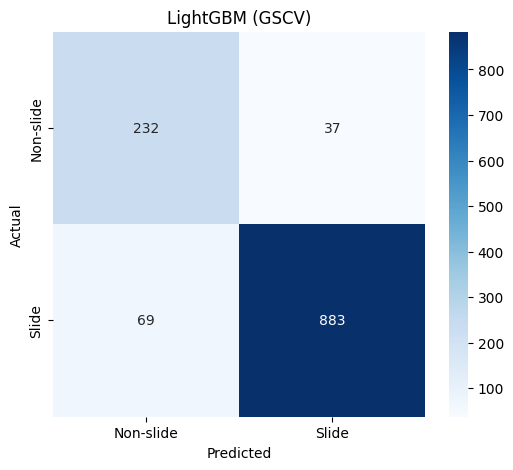

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.81       269
           1       0.96      0.93      0.94       952

    accuracy                           0.91      1221
   macro avg       0.87      0.89      0.88      1221
weighted avg       0.92      0.91      0.91      1221



In [ ]:
tuned_model_results = []

for full_model_key, model in tuned_models.items():
    if " + " in full_model_key:
        model_name, method_name = full_model_key.split(" + ")
    elif "Base " in full_model_key:
        method_name = "Base"
        model_name = full_model_key.replace("Base ", "")
    else:
        model_name = full_model_key
        method_name = "N/A"

    pipeline = Pipeline([('scaler', scaler), ('model', model)])
    res_dict = evaluate_model(f"{model_name} ({method_name})", pipeline, X, y, cv)
    res_dict["Model"] = model_name
    res_dict["Method"] = method_name
    tuned_model_results.append(res_dict)

# Ensemble

In [ ]:
estimators = [
    ('rf', rf_model_rscv),
    ('xgb', xgb_model),
    ('lgbm', lgbm_model)
]

ensemble_model_hard = VotingClassifier(estimators=estimators)

ensemble_model_hard

VotingClassifier(estimators=[('rf',
                              RandomForestClassifier(criterion='entropy',
                                                     max_depth=1000,
                                                     min_samples_leaf=2,
                                                     n_estimators=1200,
                                                     random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_m...
                                            interaction_constraints=None,
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=None, n_jobs=None,
                                            num_parallel_tree=None, ...)),
                             ('lgbm',
                              LGBMClassifier(random_state=42, verbose=-1))])

In [ ]:
ensemble_model_soft = VotingClassifier(estimators=estimators, voting='soft')

ensemble_model_soft

VotingClassifier(estimators=[('rf',
                              RandomForestClassifier(criterion='entropy',
                                                     max_depth=1000,
                                                     min_samples_leaf=2,
                                                     n_estimators=1200,
                                                     random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_m...
                                            interaction_constraints=None,
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=None, n_jobs=None,
                                            num_parallel_tree=None, ...)),
                             ('lgbm',
                              LGBMClassifier(random_state=42, verbose=-1))],
                 voting='soft')

# Ensemble Model Evaluation

In [ ]:
ensemble_models = {
    "Random Forest (Tuned)": rf_model_rscv,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model,
    "Ensemble (hard)": ensemble_model_hard,
    "Ensemble (soft)": ensemble_model_soft
}

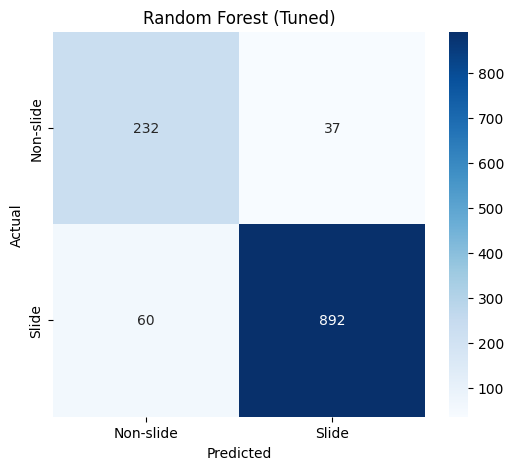

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.86      0.83       269
           1       0.96      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.90      0.89      1221
weighted avg       0.92      0.92      0.92      1221



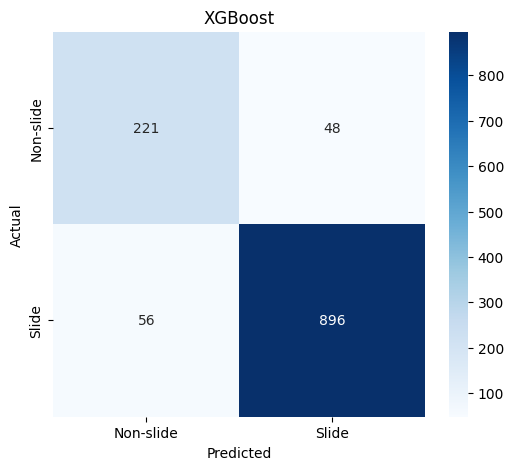

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.82      0.81       269
           1       0.95      0.94      0.95       952

    accuracy                           0.91      1221
   macro avg       0.87      0.88      0.88      1221
weighted avg       0.92      0.91      0.92      1221



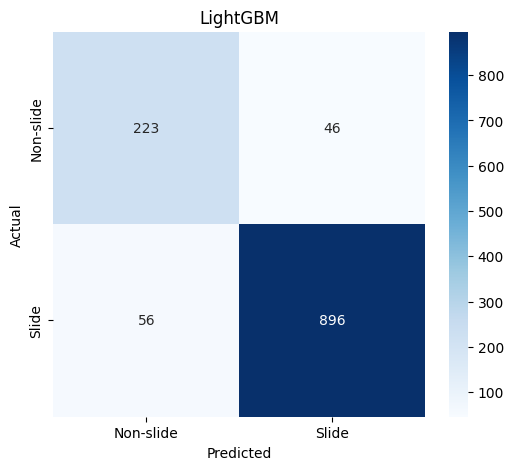

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       269
           1       0.95      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.89      0.88      1221
weighted avg       0.92      0.92      0.92      1221



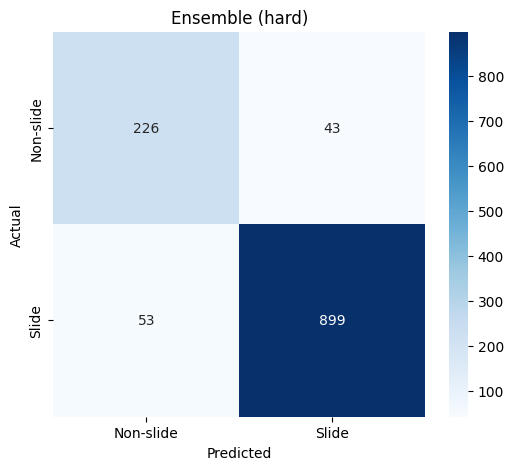

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.84      0.82       269
           1       0.95      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.89      0.89      1221
weighted avg       0.92      0.92      0.92      1221



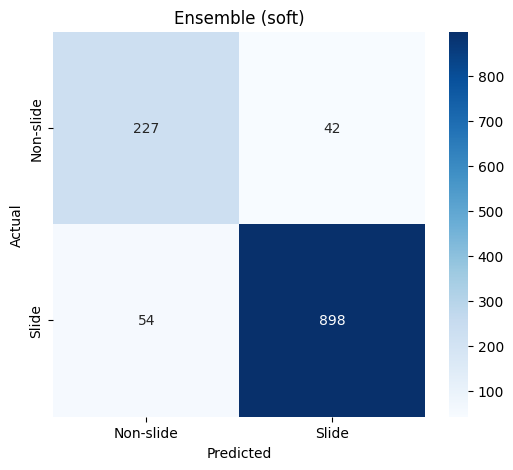

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.84      0.83       269
           1       0.96      0.94      0.95       952

    accuracy                           0.92      1221
   macro avg       0.88      0.89      0.89      1221
weighted avg       0.92      0.92      0.92      1221



In [ ]:
ensemble_model_results = []

for name, model in ensemble_models.items():
    pipeline = Pipeline([('scaler', scaler), ('model', model)])

    res_dict = evaluate_model(name, pipeline, X, y, cv)
    ensemble_model_results.append(res_dict)

ROC AUC

In [ ]:
ensemble_soft_pipeline = Pipeline([('scaler', scaler), ('model', ensemble_model_soft)])

y_scores_ensemble_soft = cross_val_predict(ensemble_soft_pipeline, X, y, cv=cv, method='predict_proba')[:, 1]

fpr_ensemble_soft, tpr_ensemble_soft, thresholds_ensemble_soft = roc_curve(y, y_scores_ensemble_soft)
roc_auc_ensemble_soft = roc_auc_score(y, y_scores_ensemble_soft)

print(f"AUC score: {roc_auc_ensemble_soft:.2f}")

AUC score: 0.97


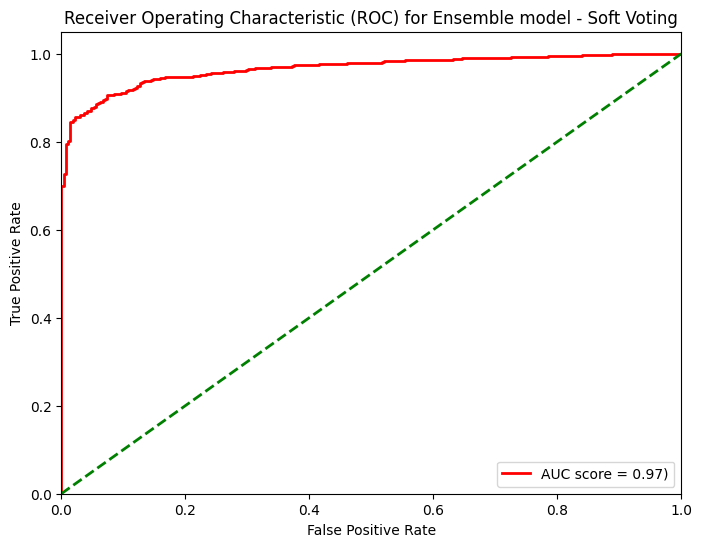

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(fpr_ensemble_soft, tpr_ensemble_soft, color='red', lw=2, label=f'AUC score = {roc_auc_ensemble_soft:.2f})')
plt.plot([0, 1], [0, 1], color='green', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) for Ensemble model - Soft Voting')
plt.legend(loc="lower right")
plt.show()

# Comparing the models

In [ ]:
results_df = pd.DataFrame(base_model_results).set_index('Model')
results_df['Rank(by Accuracy)'] = results_df['Accuracy_mean'].rank(ascending=False, method='max').astype(int)

metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
formatted_df = pd.DataFrame(index=results_df.index)

for col in metric_cols:
    mean_fmt = (results_df[f'{col}_mean'] * 100).map('{:.2f}'.format)
    std_fmt  = (results_df[f'{col}_std'] * 100).map('{:.2f}'.format)
    formatted_df[col] = mean_fmt + " ± " + std_fmt

formatted_df['Rank (by Accuracy)'] = results_df['Rank(by Accuracy)']

formatted_df

,Accuracy,Precision,Recall,F1-Score,Rank (by Accuracy)
Model,,,,,
Logistic Regression,76.91 ± 1.64,70.88 ± 6.27,76.91 ± 1.64,70.36 ± 1.94,6
Decision Tree,89.19 ± 3.66,89.33 ± 3.62,89.19 ± 3.66,89.19 ± 3.64,4
Random Forest,91.81 ± 3.26,92.21 ± 3.17,91.81 ± 3.26,91.88 ± 3.21,1
K-Nearest Neighbors,83.95 ± 2.64,84.84 ± 2.63,83.95 ± 2.64,84.16 ± 2.44,5
XGBoost,91.49 ± 3.12,91.72 ± 2.93,91.49 ± 3.12,91.54 ± 3.04,3
LightGBM,91.65 ± 3.63,91.95 ± 3.49,91.65 ± 3.63,91.71 ± 3.56,2


In [ ]:
tuning_df = pd.DataFrame(tuned_model_results)

metric_cols = ['Accuracy', 'F1-Score']

for col in metric_cols:
    mean_fmt = (tuning_df[f'{col}_mean'] * 100).map('{:.2f}'.format)
    std_fmt  = (tuning_df[f'{col}_std'] * 100).map('{:.2f}'.format)
    tuning_df[col] = mean_fmt + " ± " + std_fmt

tuning_df['Model'] = tuning_df['Model'].replace('RF', 'Random Forest')
tuning_comparison = tuning_df.pivot(index='Model', columns='Method', values=metric_cols)
tuning_comparison = tuning_comparison.swaplevel(0, 1, axis=1)
tuning_comparison = tuning_comparison.reindex(columns=['Base', 'RSCV', 'GSCV'], level=0)
tuning_comparison = tuning_comparison.reindex(
    index=['Random Forest', 'XGBoost', 'LightGBM']
)

tuning_comparison

Method                 Base                        RSCV                \
                   Accuracy      F1-Score      Accuracy      F1-Score   
Model                                                                   
Random Forest  91.81 ± 3.26  91.88 ± 3.21  92.06 ± 3.83  92.17 ± 3.72   
XGBoost        91.49 ± 3.12  91.54 ± 3.04  91.40 ± 4.14  91.53 ± 4.05   
LightGBM       91.65 ± 3.63  91.71 ± 3.56  91.32 ± 3.11  91.49 ± 3.00   

Method                 GSCV                
                   Accuracy      F1-Score  
Model                                      
Random Forest  92.06 ± 3.64  92.16 ± 3.54  
XGBoost        91.32 ± 3.75  91.49 ± 3.64  
LightGBM       91.32 ± 3.11  91.49 ± 3.00

In [ ]:
results_df = pd.DataFrame(ensemble_model_results).set_index('Model')
results_df['Rank(by Accuracy)'] = results_df['Accuracy_mean'].rank(ascending=False, method='max').astype(int)

metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
formatted_df = pd.DataFrame(index=results_df.index)

for col in metric_cols:
    mean_fmt = (results_df[f'{col}_mean'] * 100).map('{:.2f}'.format)
    std_fmt  = (results_df[f'{col}_std'] * 100).map('{:.2f}'.format)
    formatted_df[col] = mean_fmt + " ± " + std_fmt

formatted_df['Rank (by Accuracy)'] = results_df['Rank(by Accuracy)']

formatted_df

,Accuracy,Precision,Recall,F1-Score,Rank (by Accuracy)
Model,,,,,
Random Forest (Tuned),92.06 ± 3.83,92.54 ± 3.54,92.06 ± 3.83,92.17 ± 3.72,3
XGBoost,91.49 ± 3.12,91.72 ± 2.93,91.49 ± 3.12,91.54 ± 3.04,5
LightGBM,91.65 ± 3.63,91.95 ± 3.49,91.65 ± 3.63,91.71 ± 3.56,4
Ensemble (hard),92.14 ± 3.19,92.43 ± 3.07,92.14 ± 3.19,92.19 ± 3.13,2
Ensemble (soft),92.14 ± 3.10,92.44 ± 2.95,92.14 ± 3.10,92.21 ± 3.02,1


# LIME (XAI)

In [ ]:
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X.values,
    feature_names=X.columns.tolist(),
    class_names=['Non-Slide', 'Slide'],
    mode='classification',
    random_state=42
)

ensemble_pipeline = Pipeline([
    ('scaler', scaler),
    ('model', ensemble_model_soft)
])
ensemble_pipeline.fit(X, y)

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('model',
                 VotingClassifier(estimators=[('rf',
                                               RandomForestClassifier(criterion='entropy',
                                                                      max_depth=1000,
                                                                      min_samples_leaf=2,
                                                                      n_estimators=1200,
                                                                      random_state=42)),
                                              ('xgb',
                                               XGBClassifier(base_score=None,
                                                             booster=None,
                                                             callbacks=None,
                                                             colsample_bylevel=None,
                                                             colsample_bynode=None,
                                                             colsample_bytree=None,
                                                             device=None,
                                                             early_s...
                                                             interaction_constraints=None,
                                                             learning_rate=None,
                                                             max_bin=None,
                                                             max_cat_threshold=None,
                                                             max_cat_to_onehot=None,
                                                             max_delta_step=None,
                                                             max_depth=None,
                                                             max_leaves=None,
                                                             min_child_weight=None,
                                                             missing=nan,
                                                             monotone_constraints=None,
                                                             multi_strategy=None,
                                                             n_estimators=None,
                                                             n_jobs=None,
                                                             num_parallel_tree=None, ...)),
                                              ('lgbm',
                                               LGBMClassifier(random_state=42,
                                                              verbose=-1))],
                                  voting='soft'))])

In [ ]:
# Explanation for a 'Slide' Case
slide_index = y[y == 1].index[0]
slide_instance = X.loc[slide_index]

print(f"LIME Explanation for a 'Slide' Case (Row {slide_index}):")

exp_slide = explainer.explain_instance(
    data_row=slide_instance.values,
    predict_fn=ensemble_pipeline.predict_proba,
    num_features=10
)
exp_slide.show_in_notebook(show_table=True)

LIME Explanation for a 'Slide' Case (Row 0):


In [ ]:
# Explanation for a 'Non-Slide' Case
non_slide_index = y[y == 0].index[0]
non_slide_instance = X.loc[non_slide_index]

print(f"LIME Explanation for a 'Non-Slide' Case (Row {non_slide_index}):")

exp_non_slide = explainer.explain_instance(
    data_row=non_slide_instance.values,
    predict_fn=ensemble_pipeline.predict_proba,
    num_features=10
)
exp_non_slide.show_in_notebook(show_table=True)

LIME Explanation for a 'Non-Slide' Case (Row 41):
